Q1

In [3]:
import re
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from collections import Counter

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

# A unique paragraph about technology and machine learning
text = """
Machine learning is transforming modern technology.
It helps computers discover useful patterns from data.
I enjoy building Python projects and intelligent applications.
Natural language processing allows computers to analyze human language.
These technologies support chatbots, recommendation systems, and automation.
Learning artificial intelligence is both challenging and exciting!
"""

# 1. Convert to lowercase and remove punctuation using re
clean_text = re.sub(r"[^\w\s]", "", text.lower())

print("Original text:")
print(text)

print("\nCleaned text:")
print(clean_text)

# 2. Tokenize into words and sentences
word_tokens = word_tokenize(clean_text)
sentence_tokens = sent_tokenize(text)

print("\nWord tokens:")
print(word_tokens)

print("\nSentence tokens:")
print(sentence_tokens)

# 3. Compare split() and word_tokenize()
split_tokens = clean_text.split()

print("\nPython split():")
print(split_tokens)

print("\nNLTK word_tokenize():")
print(word_tokens)

print("\nAre the token lists identical?", split_tokens == word_tokens)

# 4. Remove stopwords
stop_words = set(stopwords.words("english"))

filtered_tokens = [
    word for word in word_tokens
    if word.isalpha() and word not in stop_words
]

print("\nTokens after stopword removal:")
print(filtered_tokens)

# 5. Word frequency distribution excluding stopwords
frequency = Counter(filtered_tokens)

print("\nWord frequencies:")
for word, count in frequency.most_common():
    print(f"{word}: {count}")

Original text:

Machine learning is transforming modern technology.
It helps computers discover useful patterns from data.
I enjoy building Python projects and intelligent applications.
Natural language processing allows computers to analyze human language.
These technologies support chatbots, recommendation systems, and automation.
Learning artificial intelligence is both challenging and exciting!


Cleaned text:

machine learning is transforming modern technology
it helps computers discover useful patterns from data
i enjoy building python projects and intelligent applications
natural language processing allows computers to analyze human language
these technologies support chatbots recommendation systems and automation
learning artificial intelligence is both challenging and exciting


Word tokens:
['machine', 'learning', 'is', 'transforming', 'modern', 'technology', 'it', 'helps', 'computers', 'discover', 'useful', 'patterns', 'from', 'data', 'i', 'enjoy', 'building', 'python', 'pro

Q2

In [4]:
import re
import nltk
from nltk.corpus import stopwords, wordnet
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)
nltk.download("averaged_perceptron_tagger_eng", quiet=True)

# Same paragraph as Question 1
text = """
Machine learning is transforming modern technology.
It helps computers discover useful patterns from data.
I enjoy building Python projects and intelligent applications.
Natural language processing allows computers to analyze human language.
These technologies support chatbots, recommendation systems, and automation.
Learning artificial intelligence is both challenging and exciting!
"""

# 1. Extract words containing only alphabetic characters
words = re.findall(r"\b[A-Za-z]+\b", text.lower())

print("Extracted alphabetic words:")
print(words)

# 2. Remove stopwords
stop_words = set(stopwords.words("english"))

filtered_words = [
    word for word in words
    if word not in stop_words
]

print("\nAfter stopword removal:")
print(filtered_words)

# 3. Porter stemming
porter = PorterStemmer()
stemmed_words = [porter.stem(word) for word in filtered_words]

print("\nPorter-stemmed words:")
print(stemmed_words)

# 4. WordNet lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_words = [
    lemmatizer.lemmatize(word)
    for word in filtered_words
]

print("\nWordNet-lemmatized words:")
print(lemmatized_words)

# 5. Compare the outputs word by word
comparison = list(zip(filtered_words, stemmed_words, lemmatized_words))

print("\nOriginal | Stemmed | Lemmatized")
for original, stem, lemma in comparison:
    print(f"{original:18} | {stem:15} | {lemma}")

# Optional: POS-aware lemmatization
def get_wordnet_pos(tag):
    if tag.startswith("J"):
        return wordnet.ADJ
    if tag.startswith("V"):
        return wordnet.VERB
    if tag.startswith("N"):
        return wordnet.NOUN
    if tag.startswith("R"):
        return wordnet.ADV
    return wordnet.NOUN

tagged_words = pos_tag(filtered_words)

pos_lemmas = [
    lemmatizer.lemmatize(word, get_wordnet_pos(tag))
    for word, tag in tagged_words
]

print("\nPOS-aware lemmatization:")
print(pos_lemmas)

Extracted alphabetic words:
['machine', 'learning', 'is', 'transforming', 'modern', 'technology', 'it', 'helps', 'computers', 'discover', 'useful', 'patterns', 'from', 'data', 'i', 'enjoy', 'building', 'python', 'projects', 'and', 'intelligent', 'applications', 'natural', 'language', 'processing', 'allows', 'computers', 'to', 'analyze', 'human', 'language', 'these', 'technologies', 'support', 'chatbots', 'recommendation', 'systems', 'and', 'automation', 'learning', 'artificial', 'intelligence', 'is', 'both', 'challenging', 'and', 'exciting']

After stopword removal:
['machine', 'learning', 'transforming', 'modern', 'technology', 'helps', 'computers', 'discover', 'useful', 'patterns', 'data', 'enjoy', 'building', 'python', 'projects', 'intelligent', 'applications', 'natural', 'language', 'processing', 'allows', 'computers', 'analyze', 'human', 'language', 'technologies', 'support', 'chatbots', 'recommendation', 'systems', 'automation', 'learning', 'artificial', 'intelligence', 'challeng

Q3

In [9]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# Three original texts about different topics
texts = [
    "Artificial intelligence helps computers learn patterns from data.",
    "Blockchain technology provides secure decentralized digital transactions.",
    "Machine learning uses data to build predictive computer models."
]

# 1. Bag of Words
bow_vectorizer = CountVectorizer()
bow_matrix = bow_vectorizer.fit_transform(texts)

bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=bow_vectorizer.get_feature_names_out(),
    index=["Text 1", "Text 2", "Text 3"]
)

print("BAG OF WORDS:")
print(bow_df)

# 2. TF-IDF representation
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=["Text 1", "Text 2", "Text 3"]
)

print("\nTF-IDF SCORES:")
print(tfidf_df.round(3))

# 3. Top 3 keywords for each text
feature_names = tfidf_vectorizer.get_feature_names_out()
print(feature_names)

print("\nTOP 3 KEYWORDS PER TEXT:")

for i, row in enumerate(tfidf_matrix.toarray()):
    top_indices = row.argsort()[-3:][::-1]

    top_keywords = [
        (feature_names[index], round(row[index], 3))
        for index in top_indices
    ]

    print(f"Text {i + 1}: {top_keywords}")

BAG OF WORDS:
        artificial  blockchain  build  computer  computers  data  \
Text 1           1           0      0         0          1     1   
Text 2           0           1      0         0          0     0   
Text 3           0           0      1         1          0     1   

        decentralized  digital  from  helps  ...  machine  models  patterns  \
Text 1              0        0     1      1  ...        0       0         1   
Text 2              1        1     0      0  ...        0       0         0   
Text 3              0        0     0      0  ...        1       1         0   

        predictive  provides  secure  technology  to  transactions  uses  
Text 1           0         0       0           0   0             0     0  
Text 2           0         1       1           1   0             1     0  
Text 3           1         0       0           0   1             0     1  

[3 rows x 23 columns]

TF-IDF SCORES:
        artificial  blockchain  build  computer  computer

Q4

In [10]:
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Two short technology descriptions (4-6 lines each)
text_ai = """
Artificial intelligence enables machines to perform intelligent tasks.
Machine learning helps systems learn patterns from data.
AI supports image recognition and language understanding.
Intelligent systems can automate complex decisions.
"""

text_blockchain = """
Blockchain stores digital transactions in a distributed ledger.
Cryptography helps protect blockchain records from tampering.
Blockchain networks support decentralized financial applications.
Distributed systems maintain shared transaction histories.
"""

# 1. Preprocess and tokenize
def preprocess(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    tokens = text.split()
    return tokens

tokens_ai = preprocess(text_ai)
tokens_blockchain = preprocess(text_blockchain)

print("AI tokens:")
print(tokens_ai)

print("\nBlockchain tokens:")
print(tokens_blockchain)

# 2(a). Jaccard similarity using sets
set_ai = set(tokens_ai)
set_blockchain = set(tokens_blockchain)

intersection = set_ai & set_blockchain
union = set_ai | set_blockchain

jaccard = len(intersection) / len(union) if union else 0

print("\nCommon words:", intersection)
print("Jaccard Similarity:", round(jaccard, 4))

# 2(b). Cosine similarity using TF-IDF
vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform([
    " ".join(tokens_ai),
    " ".join(tokens_blockchain)
])

cosine = cosine_similarity(
    tfidf_matrix[0:1],
    tfidf_matrix[1:2]
)[0, 0]

print("Cosine Similarity:", round(cosine, 4))

# 2(c). Compare the results
print("\nINTERPRETATION:")

if cosine > jaccard:
    print("Cosine similarity is higher than Jaccard similarity.")
elif cosine < jaccard:
    print("Jaccard similarity is higher than cosine similarity.")
else:
    print("Both similarity scores are equal.")

print(
    "Jaccard compares the proportion of shared unique words. "
    "Cosine compares the angle between TF-IDF vectors, "
    "accounting for word weights."
)

AI tokens:
['artificial', 'intelligence', 'enables', 'machines', 'to', 'perform', 'intelligent', 'tasks', 'machine', 'learning', 'helps', 'systems', 'learn', 'patterns', 'from', 'data', 'ai', 'supports', 'image', 'recognition', 'and', 'language', 'understanding', 'intelligent', 'systems', 'can', 'automate', 'complex', 'decisions']

Blockchain tokens:
['blockchain', 'stores', 'digital', 'transactions', 'in', 'a', 'distributed', 'ledger', 'cryptography', 'helps', 'protect', 'blockchain', 'records', 'from', 'tampering', 'blockchain', 'networks', 'support', 'decentralized', 'financial', 'applications', 'distributed', 'systems', 'maintain', 'shared', 'transaction', 'histories']

Common words: {'from', 'helps', 'systems'}
Jaccard Similarity: 0.0625
Cosine Similarity: 0.0648

INTERPRETATION:
Cosine similarity is higher than Jaccard similarity.
Jaccard compares the proportion of shared unique words. Cosine compares the angle between TF-IDF vectors, accounting for word weights.


Q5

SENTIMENT ANALYSIS RESULTS:


,Review,Polarity,Subjectivity,Sentiment
0,"The laptop is fast, reliable, and has an excel...",0.600,0.800,Positive
1,The camera quality is amazing and the pictures...,0.725,0.950,Positive
2,Customer service was helpful and solved my pro...,0.333,0.500,Positive
3,The phone is disappointing and the battery dra...,-0.083,0.675,Negative
4,The product is poorly made and the performance...,-0.700,0.800,Negative
5,The delivery was delayed and the packaging was...,0.000,0.000,Neutral
6,The product arrived yesterday.,0.000,0.000,Neutral
7,The laptop has a screen and a keyboard.,0.000,0.000,Neutral



Positive reviews:
- The laptop is fast, reliable, and has an excellent battery.
- The camera quality is amazing and the pictures look beautiful.
- Customer service was helpful and solved my problem quickly.


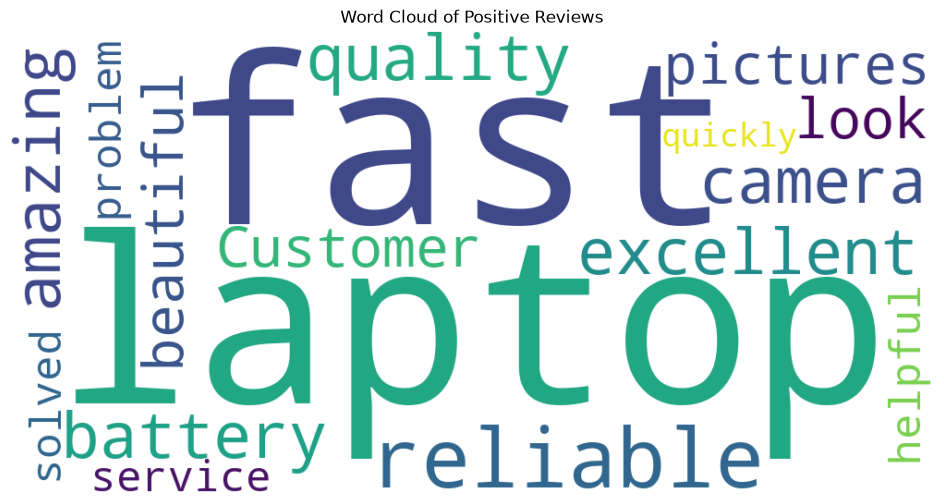

In [16]:
# If necessary, run this once in Google Colab:
# %pip install textblob wordcloud

import nltk
import pandas as pd
import matplotlib.pyplot as plt
from textblob import TextBlob
from wordcloud import WordCloud

nltk.download("punkt", quiet=True)

# Product and service reviews
reviews = [
    "The laptop is fast, reliable, and has an excellent battery.",
    "The camera quality is amazing and the pictures look beautiful.",
    "Customer service was helpful and solved my problem quickly.",
    "The phone is disappointing and the battery drains very quickly.",
    "The product is poorly made and the performance is terrible.",
    "The delivery was delayed and the packaging was damaged.",
    "The product arrived yesterday.",
    "The laptop has a screen and a keyboard."
]

results = []

# 1. Calculate polarity and subjectivity
# 2. Classify each review
for review in reviews:
    blob = TextBlob(review)

    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    results.append({
        "Review": review,
        "Polarity": round(polarity, 3),
        "Subjectivity": round(subjectivity, 3),
        "Sentiment": sentiment
    })

results_df = pd.DataFrame(results)

print("SENTIMENT ANALYSIS RESULTS:")
display(results_df)

# 3. Collect positive reviews
positive_reviews = results_df.loc[
    results_df["Sentiment"] == "Positive", "Review"
].tolist()

print("\nPositive reviews:")
for review in positive_reviews:
    print("-", review)

# 4. Generate a word cloud using positive reviews
if positive_reviews:
    positive_text = " ".join(positive_reviews)

    wordcloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        collocations=False
    ).generate(positive_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews were found.")

Q6

In [4]:
import numpy as np
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Step 1: Choose a paragraph of approximately 100 words
text = """
Technology is changing the world in many ways.
Artificial intelligence helps computers learn from data and solve problems.
Machine learning allows systems to identify patterns and make predictions.
Students use technology to improve their knowledge and develop new skills.
Programming teaches logical thinking and helps people build useful applications.
Python is a popular language for artificial intelligence and data science.
Deep learning uses neural networks to learn complex patterns from large datasets.
Data plays an important role in training intelligent systems.
Modern applications use technology to make everyday tasks easier.
Learning new technologies helps students prepare for future opportunities.
Artificial intelligence and machine learning are transforming healthcare,
education, transportation, and communication.
With consistent practice, students can develop the skills needed to
solve real-world problems and create innovative solutions.
"""

# Step 2: Tokenize the text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([text])

total_words = len(tokenizer.word_index) + 1

print("Total unique words:", total_words)
print("Word index:", tokenizer.word_index)

# Step 3: Create input sequences
tokens = tokenizer.texts_to_sequences([text])[0]

sequences = []

for i in range(1, len(tokens)):
    sequence = tokens[:i + 1]
    sequences.append(sequence)

print("\nFirst five sequences:")
for sequence in sequences[:5]:
    print(sequence)

# Step 4: Pad the sequences
max_seq_len = max(len(sequence) for sequence in sequences)

sequences = pad_sequences(
    sequences,
    maxlen=max_seq_len,
    padding="pre"
)

print("\nPadded sequence shape:", sequences.shape)

# Step 5: Split sequences into input (X) and output (y)
X = sequences[:, :-1]
y = sequences[:, -1]

print("X shape:", X.shape)
print("y shape:", y.shape)

# Step 6: Build the LSTM model
model = Sequential([
    Embedding(
        input_dim=total_words,
        output_dim=16,
        input_length=max_seq_len - 1
    ),
    LSTM(64),
    Dense(total_words, activation="softmax")
])

# Step 7: Compile the model
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

# Step 8: Train the model
model.fit(
    X,
    y,
    epochs=200,
    verbose=0
)

print("\nModel training completed!")

# Step 9: Generate new text
def generate_text(seed_text, next_words=12):
    generated_text = seed_text

    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences(
            [generated_text]
        )[0]

        token_list = pad_sequences(
            [token_list],
            maxlen=X.shape[1],
            padding="pre"
        )

        predicted = model.predict(token_list, verbose=0)

        predicted_word_index = np.argmax(predicted)

        predicted_word = tokenizer.index_word.get(
            predicted_word_index, ""
        )

        if not predicted_word:
            break

        generated_text += " " + predicted_word

    return generated_text

# Generate three lines using different seed phrases
print("\nGenerated Text:\n")

print("1.", generate_text("technology is", 12))
print("2.", generate_text("machine learning", 12))
print("3.", generate_text("students use", 12))

Total unique words: 86
Word index: {'and': 1, 'to': 2, 'learning': 3, 'technology': 4, 'artificial': 5, 'intelligence': 6, 'helps': 7, 'data': 8, 'students': 9, 'is': 10, 'the': 11, 'world': 12, 'in': 13, 'learn': 14, 'from': 15, 'solve': 16, 'problems': 17, 'machine': 18, 'systems': 19, 'patterns': 20, 'make': 21, 'use': 22, 'develop': 23, 'new': 24, 'skills': 25, 'applications': 26, 'for': 27, 'changing': 28, 'many': 29, 'ways': 30, 'computers': 31, 'allows': 32, 'identify': 33, 'predictions': 34, 'improve': 35, 'their': 36, 'knowledge': 37, 'programming': 38, 'teaches': 39, 'logical': 40, 'thinking': 41, 'people': 42, 'build': 43, 'useful': 44, 'python': 45, 'a': 46, 'popular': 47, 'language': 48, 'science': 49, 'deep': 50, 'uses': 51, 'neural': 52, 'networks': 53, 'complex': 54, 'large': 55, 'datasets': 56, 'plays': 57, 'an': 58, 'important': 59, 'role': 60, 'training': 61, 'intelligent': 62, 'modern': 63, 'everyday': 64, 'tasks': 65, 'easier': 66, 'technologies': 67, 'prepare': 68

C:\Users\Kaif Ahmad\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Model training completed!

Generated Text:

1. technology is is is changing in many ways artificial intelligence helps computers learn from
2. machine learning the world in many ways artificial intelligence intelligence computers computers from from
3. students use is changing the many many ways artificial intelligence helps computers learn from
